# GPU-resident CUDA BHO benchmark (Google Colab)

This notebook runs a **real CUDA implementation** on an NVIDIA GPU and compares it with sequential CPU, OpenMP CPU, and CUDA implementations using the same search equations.

**What executes on the GPU:** population initialization, candidate generation, objective-function evaluation, and greedy selection. The population and fitness arrays stay in device memory throughout the optimization loop; only the final best score is copied back. The global-best scan is also launched on the GPU (currently a simple one-thread scan, which can be optimized later).

**Important algorithm note:** the original BHO source includes K-means representative/group initialization, QPRS reassignment, and Explorpolis diversity admission. This notebook implements a GPU-resident **BHO-inspired variant of its best-guided/peer-guided search**, not a line-by-line CUDA port of every mechanism in the paper. Its CPU and CUDA versions are matched to each other for fair timing and score comparisons. Do not describe it as an exact reproduction of the paper's full BHO algorithm.


## 1. Select an NVIDIA GPU runtime

In Colab: **Runtime → Change runtime type → T4 GPU** (or another available GPU), then run the cells from top to bottom. This notebook deliberately stops if CUDA tools or an NVIDIA GPU are unavailable.


In [1]:
import torch
import time

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    # Allocate data directly on the GPU
    a = torch.randn((4096, 4096), device="cuda")
    b = torch.randn((4096, 4096), device="cuda")

    torch.cuda.synchronize()
    start = time.perf_counter()

    for _ in range(30):
        c = torch.matmul(a, b)

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    print(f"GPU computation completed in {elapsed:.3f} seconds")
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**2, 1),
        "MiB"
    )
else:
    print("CUDA is unavailable to PyTorch.")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU computation completed in 1.115 seconds
GPU memory allocated: 200.1 MiB


In [2]:
import os, shutil, subprocess, time
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

print("nvidia-smi:", shutil.which("nvidia-smi"))
print("nvcc:", shutil.which("nvcc"))
if shutil.which("nvidia-smi") is None:
    raise RuntimeError("No NVIDIA GPU detected. Choose Runtime > Change runtime type > GPU.")
if shutil.which("nvcc") is None:
    raise RuntimeError("nvcc is unavailable in this runtime. Restart after selecting GPU or use a Colab runtime with CUDA Toolkit.")
subprocess.run(["nvidia-smi"], check=True)


nvidia-smi: /opt/bin/nvidia-smi
nvcc: /usr/local/cuda/bin/nvcc


CompletedProcess(args=['nvidia-smi'], returncode=0)

In [ ]:
!nvidia-smi -l 1

Fri Oct 23 02:44:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P0             25W /   70W |     393MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Write the CPU and CUDA source files

The sources are embedded in this notebook, so you do not need to upload separate `.cpp` or `.cu` files.


In [3]:
cpu_source = '// CPU baseline for the same GPU-resident BHO-inspired variant.\n// Designed for a fair CPU-vs-CUDA timing comparison of the same search/update equations.\n#include <algorithm>\n#include <chrono>\n#include <cmath>\n#include <cstdlib>\n#include <iomanip>\n#include <iostream>\n#include <string>\n#include <vector>\nconstexpr double PI=3.14159265358979323846;\nstruct Bench { const char* name; int id; double lb,ub; };\nstatic unsigned int hash32(unsigned int x) {\n    x^=x>>16; x*=0x7feb352dU; x^=x>>15; x*=0x846ca68bU; x^=x>>16; return x;\n}\nstatic double rand01(unsigned int seed,unsigned int a,unsigned int b) {\n    unsigned int x=hash32(seed^(a*0x9e3779b9U)^(b*0x85ebca6bU));\n    return (double)(x&0x00ffffffU)/16777216.0;\n}\nstatic double objective(const double* x,int D,int id) {\n    double s=0.0;\n    if(id==0){for(int j=0;j<D;j++)s+=x[j]*x[j];return s;}\n    if(id==1){s=10.0*D;for(int j=0;j<D;j++)s+=x[j]*x[j]-10.0*cos(2.0*PI*x[j]);return s;}\n    if(id==2){for(int j=0;j<D-1;j++){double a=x[j+1]-x[j]*x[j],b=x[j]-1.0;s+=100.0*a*a+b*b;}return s;}\n    if(id==3){double s1=0,s2=0;for(int j=0;j<D;j++){s1+=x[j]*x[j];s2+=cos(2.0*PI*x[j]);}return -20.0*exp(-0.2*sqrt(s1/D))-exp(s2/D)+20.0+exp(1.0);}\n    if(id==4){double p=1.0;for(int j=0;j<D;j++){s+=x[j]*x[j]/4000.0;p*=cos(x[j]/sqrt((double)(j+1)));}return s-p+1.0;}\n    for(int j=0;j<D;j++)s+=x[j]*sin(sqrt(fabs(x[j])));\n    return 418.9829*D-s;\n}\nint main(int argc,char** argv) {\n    int D=argc>1?std::atoi(argv[1]):30;\n    int N=argc>2?std::atoi(argv[2]):256;\n    int max_iter=argc>3?std::atoi(argv[3]):300;\n    int repeats=argc>4?std::atoi(argv[4]):3;\n    if(D<2||N<2||max_iter<1||repeats<1){std::cerr<<"Usage: ./bho_cpu D N iterations repeats\\n";return 1;}\n    Bench tests[]={{"Sphere",0,-100,100},{"Rastrigin",1,-5.12,5.12},{"Rosenbrock",2,-30,30},\n                   {"Ackley",3,-32.768,32.768},{"Griewank",4,-600,600},{"Schwefel",5,-500,500}};\n    std::cout<<"function,dimension,population,repeat,best_score,seconds\\n";\n    for(const auto& b:tests)for(int rep=0;rep<repeats;rep++){\n        std::vector<double>X((size_t)N*D),F(N),T((size_t)N*D),FT(N),Xnext((size_t)N*D),Fnext(N);\n        unsigned int seed=12345u+(unsigned int)rep*101u+(unsigned int)b.id*1009u;\n        auto start=std::chrono::steady_clock::now();\n        for(int i=0;i<N;i++){\n            double* xi=&X[(size_t)i*D];\n            for(int j=0;j<D;j++)xi[j]=b.lb+(b.ub-b.lb)*rand01(seed,(unsigned)i,(unsigned)j);\n            F[i]=objective(xi,D,b.id);\n        }\n        int bi=0;\n        for(int it=0;it<max_iter;it++){\n            bi=0;for(int i=1;i<N;i++)if(F[i]<F[bi])bi=i;\n            for(int i=0;i<N;i++){\n                const double* xi=&X[(size_t)i*D]; const double* xb=&X[(size_t)bi*D];\n                int peer=(int)(rand01(seed,(unsigned)i,(unsigned)(it*17+3))*N);\n                if(peer==i)peer=(peer+1)%N;\n                const double* xp=&X[(size_t)peer*D];\n                double fi=F[i],fp=F[peer],progress=(double)it/(double)max_iter,m=1.0-0.5*progress;\n                double* ti=&T[(size_t)i*D];\n                for(int j=0;j<D;j++){\n                    double r1=rand01(seed,(unsigned)i,(unsigned)(it*31+j*3+1));\n                    double r2=rand01(seed,(unsigned)i,(unsigned)(it*31+j*3+2));\n                    double r3=rand01(seed,(unsigned)i,(unsigned)(it*31+j*3+3));\n                    double candidate;\n                    if(rand01(seed,(unsigned)i,(unsigned)(it+7919))<0.65)\n                        candidate=xi[j]+m*(r1*(xb[j]-xi[j])+0.35*r2*(xp[j]-xi[j]));\n                    else {\n                        double step=r1*(xp[j]-xi[j]);\n                        candidate=(fp<fi?xi[j]+step:xi[j]-step);\n                        candidate+=(r2-0.5)*m*0.2*(b.ub-b.lb)*r3;\n                    }\n                    ti[j]=std::min(b.ub,std::max(b.lb,candidate));\n                }\n                FT[i]=objective(ti,D,b.id);\n            }\n            for(int i=0;i<N;i++){\n                const double* oldx=&X[(size_t)i*D];const double* trial=&T[(size_t)i*D];\n                double* out=&Xnext[(size_t)i*D];\n                if(FT[i]<F[i]){std::copy(trial,trial+D,out);Fnext[i]=FT[i];}\n                else{std::copy(oldx,oldx+D,out);Fnext[i]=F[i];}\n            }\n            X.swap(Xnext);F.swap(Fnext);\n        }\n        bi=0;for(int i=1;i<N;i++)if(F[i]<F[bi])bi=i;\n        auto stop=std::chrono::steady_clock::now();\n        double sec=std::chrono::duration<double>(stop-start).count();\n        std::cout<<b.name<<","<<D<<","<<N<<","<<rep<<","<<std::setprecision(12)<<F[bi]<<","<<sec<<"\\n";\n    }\n    return 0;\n}\n'

cuda_source = '// GPU-resident BHO-style optimizer (CUDA C++)\n// Population, candidate generation, objective evaluation, greedy selection, and best tracking\n// execute on the NVIDIA GPU. This is a GPU-resident BHO-inspired variant, not a line-by-line\n// reproduction of the paper\'s K-means/QPRS/Explorpolis implementation.\n#include <cuda_runtime.h>\n#include <algorithm>\n#include <utility>\n#include <cstdio>\n#include <cstdlib>\n#include <cmath>\n#include <cstring>\n#include <chrono>\n#include <iostream>\n#include <iomanip>\n#include <string>\n#include <vector>\n\n#define CUDA_CHECK(call) do { cudaError_t e=(call); if(e!=cudaSuccess){ \\\n  std::cerr << "CUDA error: " << cudaGetErrorString(e) << " at " << __FILE__ << ":" << __LINE__ << "\\n"; \\\n  std::exit(2); }} while(0)\n\nconstexpr double PI = 3.14159265358979323846;\n\nstruct Bench {\n    const char* name;\n    int id;\n    double lb, ub;\n};\n\n__device__ unsigned int hash32(unsigned int x) {\n    x ^= x >> 16; x *= 0x7feb352dU; x ^= x >> 15;\n    x *= 0x846ca68bU; x ^= x >> 16;\n    return x;\n}\n__device__ double rand01(unsigned int seed, unsigned int a, unsigned int b) {\n    unsigned int x = hash32(seed ^ (a * 0x9e3779b9U) ^ (b * 0x85ebca6bU));\n    return (double)(x & 0x00ffffffU) / 16777216.0;\n}\n\n__device__ double objective(const double* x, int D, int id) {\n    double s=0.0;\n    if (id==0) { // Sphere\n        for(int j=0;j<D;j++) s += x[j]*x[j];\n        return s;\n    }\n    if (id==1) { // Rastrigin\n        s=10.0*D;\n        for(int j=0;j<D;j++) s += x[j]*x[j]-10.0*cos(2.0*PI*x[j]);\n        return s;\n    }\n    if (id==2) { // Rosenbrock\n        for(int j=0;j<D-1;j++) {\n            double a=x[j+1]-x[j]*x[j], b=x[j]-1.0;\n            s += 100.0*a*a+b*b;\n        }\n        return s;\n    }\n    if (id==3) { // Ackley\n        double s1=0.0,s2=0.0;\n        for(int j=0;j<D;j++){s1+=x[j]*x[j];s2+=cos(2.0*PI*x[j]);}\n        return -20.0*exp(-0.2*sqrt(s1/D))-exp(s2/D)+20.0+exp(1.0);\n    }\n    if (id==4) { // Griewank\n        double p=1.0;\n        for(int j=0;j<D;j++){s+=x[j]*x[j]/4000.0;p*=cos(x[j]/sqrt((double)(j+1)));}\n        return s-p+1.0;\n    }\n    // Schwefel\n    for(int j=0;j<D;j++) s += x[j]*sin(sqrt(fabs(x[j])));\n    return 418.9829*D-s;\n}\n\n__global__ void init_population(double* X, double* F, int N, int D,\n                                double lb, double ub, unsigned int seed, int obj) {\n    int i=blockIdx.x*blockDim.x+threadIdx.x;\n    if(i>=N) return;\n    double* xi=X+(size_t)i*D;\n    for(int j=0;j<D;j++) xi[j]=lb+(ub-lb)*rand01(seed,(unsigned)i,(unsigned)j);\n    F[i]=objective(xi,D,obj);\n}\n\n__global__ void find_best(const double* F, int N, int* best_idx, double* best_f) {\n    if(blockIdx.x || threadIdx.x) return;\n    int bi=0; double bf=F[0];\n    for(int i=1;i<N;i++) if(F[i]<bf){bf=F[i];bi=i;}\n    *best_idx=bi; *best_f=bf;\n}\n\n// Each CUDA thread owns one hunter. It reads the current population and best position,\n// constructs a candidate using best-guided exploitation plus peer-guided exploration,\n// evaluates it, and applies greedy selection. X/F remain resident on device.\n__global__ void update_hunters(const double* X, const double* F, double* T, double* FT,\n                               int N, int D, double lb, double ub, int obj,\n                               const int* best_idx, const double* best_f,\n                               unsigned int seed, int iter, int max_iter) {\n    int i=blockIdx.x*blockDim.x+threadIdx.x;\n    if(i>=N) return;\n    int bi=*best_idx;\n    const double* xi=X+(size_t)i*D;\n    const double* xb=X+(size_t)bi*D;\n    int peer=(int)(rand01(seed,(unsigned)i,(unsigned)(iter*17+3))*N);\n    if(peer==i) peer=(peer+1)%N;\n    const double* xp=X+(size_t)peer*D;\n    double fi=F[i], fp=F[peer];\n    double progress=(double)iter/(double)max_iter;\n    double m=1.0-0.5*progress;\n    double* ti=T+(size_t)i*D;\n    for(int j=0;j<D;j++) {\n        double r1=rand01(seed,(unsigned)i,(unsigned)(iter*31+j*3+1));\n        double r2=rand01(seed,(unsigned)i,(unsigned)(iter*31+j*3+2));\n        double r3=rand01(seed,(unsigned)i,(unsigned)(iter*31+j*3+3));\n        double candidate;\n        if(rand01(seed,(unsigned)i,(unsigned)(iter+7919)) < 0.65) {\n            // exploitation: move toward global best with a peer/personal perturbation\n            candidate=xi[j]+m*(r1*(xb[j]-xi[j])+0.35*r2*(xp[j]-xi[j]));\n        } else {\n            // exploration: step relative to a peer, direction based on fitness\n            double step=r1*(xp[j]-xi[j]);\n            candidate=(fp<fi ? xi[j]+step : xi[j]-step);\n            candidate += (r2-0.5)*m*0.2*(ub-lb)*r3;\n        }\n        candidate=fmin(ub,fmax(lb,candidate));\n        ti[j]=candidate;\n    }\n    double ft=objective(ti,D,obj);\n    FT[i]=ft;\n}\n\n__global__ void select_next(const double* X, const double* F, const double* T, const double* FT,\n                            double* Xnext, double* Fnext, int N, int D) {\n    int i=blockIdx.x*blockDim.x+threadIdx.x;\n    if(i>=N) return;\n    const double* oldx=X+(size_t)i*D;\n    const double* trial=T+(size_t)i*D;\n    double* out=Xnext+(size_t)i*D;\n    if(FT[i] < F[i]) {\n        for(int j=0;j<D;j++) out[j]=trial[j];\n        Fnext[i]=FT[i];\n    } else {\n        for(int j=0;j<D;j++) out[j]=oldx[j];\n        Fnext[i]=F[i];\n    }\n}\n\nint main(int argc,char** argv) {\n    int D = argc>1 ? std::atoi(argv[1]) : 30;\n    int N = argc>2 ? std::atoi(argv[2]) : 256;\n    int max_iter = argc>3 ? std::atoi(argv[3]) : 300;\n    int repeats = argc>4 ? std::atoi(argv[4]) : 3;\n    if(D<2 || N<2 || max_iter<1 || repeats<1) {\n        std::cerr<<"Usage: ./bho_cuda D N iterations repeats\\n"; return 1;\n    }\n\n    int device=0; cudaDeviceProp prop{};\n    CUDA_CHECK(cudaGetDevice(&device)); CUDA_CHECK(cudaGetDeviceProperties(&prop,device));\n    std::cerr<<"GPU,"<<prop.name<<"\\n";\n    Bench tests[]={{"Sphere",0,-100,100},{"Rastrigin",1,-5.12,5.12},\n                   {"Rosenbrock",2,-30,30},{"Ackley",3,-32.768,32.768},\n                   {"Griewank",4,-600,600},{"Schwefel",5,-500,500}};\n    std::cout<<"function,dimension,population,repeat,best_score,seconds\\n";\n    for(const auto& b:tests) {\n        for(int rep=0;rep<repeats;rep++) {\n            double *dX=nullptr,*dF=nullptr,*dT=nullptr,*dFT=nullptr,*dXnext=nullptr,*dFnext=nullptr,*dBestF=nullptr;\n            int *dBestIdx=nullptr;\n            CUDA_CHECK(cudaMalloc(&dX,(size_t)N*D*sizeof(double)));\n            CUDA_CHECK(cudaMalloc(&dF,(size_t)N*sizeof(double)));\n            CUDA_CHECK(cudaMalloc(&dT,(size_t)N*D*sizeof(double)));\n            CUDA_CHECK(cudaMalloc(&dFT,(size_t)N*sizeof(double)));\n            CUDA_CHECK(cudaMalloc(&dXnext,(size_t)N*D*sizeof(double)));\n            CUDA_CHECK(cudaMalloc(&dFnext,(size_t)N*sizeof(double)));\n            CUDA_CHECK(cudaMalloc(&dBestF,sizeof(double)));\n            CUDA_CHECK(cudaMalloc(&dBestIdx,sizeof(int)));\n            const unsigned int seed=12345u+(unsigned int)rep*101u+(unsigned int)b.id*1009u;\n            int threads=128, blocks=(N+threads-1)/threads;\n\n            CUDA_CHECK(cudaDeviceSynchronize());\n            auto start=std::chrono::steady_clock::now();\n            init_population<<<blocks,threads>>>(dX,dF,N,D,b.lb,b.ub,seed,b.id);\n            CUDA_CHECK(cudaGetLastError());\n            for(int it=0;it<max_iter;it++) {\n                find_best<<<1,1>>>(dF,N,dBestIdx,dBestF);\n                CUDA_CHECK(cudaGetLastError());\n                update_hunters<<<blocks,threads>>>(dX,dF,dT,dFT,N,D,b.lb,b.ub,b.id,dBestIdx,dBestF,seed,it,max_iter);\n                CUDA_CHECK(cudaGetLastError());\n                select_next<<<blocks,threads>>>(dX,dF,dT,dFT,dXnext,dFnext,N,D);\n                CUDA_CHECK(cudaGetLastError());\n                std::swap(dX,dXnext);\n                std::swap(dF,dFnext);\n            }\n            find_best<<<1,1>>>(dF,N,dBestIdx,dBestF);\n            CUDA_CHECK(cudaGetLastError());\n            CUDA_CHECK(cudaDeviceSynchronize());\n            auto stop=std::chrono::steady_clock::now();\n            double score=0.0;\n            CUDA_CHECK(cudaMemcpy(&score,dBestF,sizeof(double),cudaMemcpyDeviceToHost));\n            double sec=std::chrono::duration<double>(stop-start).count();\n            std::cout<<b.name<<","<<D<<","<<N<<","<<rep<<","<<std::setprecision(12)<<score<<","<<sec<<"\\n";\n            cudaFree(dX);cudaFree(dF);cudaFree(dT);cudaFree(dFT);cudaFree(dXnext);cudaFree(dFnext);cudaFree(dBestF);cudaFree(dBestIdx);\n        }\n    }\n    return 0;\n}\n'

with open("bho_cpu_comparison.cpp", "w", encoding="utf-8") as f:
    f.write(cpu_source)
with open("bho_cuda_gpu_resident.cu", "w", encoding="utf-8") as f:
    f.write(cuda_source)

print("CPU source bytes:", os.path.getsize("bho_cpu_comparison.cpp"))
print("CUDA source bytes:", os.path.getsize("bho_cuda_gpu_resident.cu"))


CPU source bytes: 4556
CUDA source bytes: 8377


In [4]:
# Create an OpenMP implementation from the same C++ algorithm and benchmark functions.
# Only independent per-hunter loops are parallelized; best-index scans remain sequential.
omp_source = cpu_source.replace(
    """        for(int i=0;i<N;i++){
            double* xi=&X[(size_t)i*D];""",
    """        #pragma omp parallel for schedule(static)
        for(int i=0;i<N;i++){
            double* xi=&X[(size_t)i*D];"""
).replace(
    """            for(int i=0;i<N;i++){
                const double* xi=&X[(size_t)i*D];""",
    """            #pragma omp parallel for schedule(static)
            for(int i=0;i<N;i++){
                const double* xi=&X[(size_t)i*D];"""
).replace(
    """            for(int i=0;i<N;i++){
                const double* oldx=&X[(size_t)i*D];""",
    """            #pragma omp parallel for schedule(static)
            for(int i=0;i<N;i++){
                const double* oldx=&X[(size_t)i*D];"""
)
if omp_source == cpu_source or omp_source.count("#pragma omp parallel for") != 3:
    raise RuntimeError("OpenMP source transformation failed.")
with open("bho_openmp.cpp", "w", encoding="utf-8") as f:
    f.write(omp_source)
print("Created bho_openmp.cpp with", omp_source.count("#pragma omp parallel for"), "parallel loops.")


Created bho_openmp.cpp with 3 parallel loops.


## 3. Compile sequential, OpenMP, and CUDA programs

The OpenMP version uses `g++ -fopenmp`. It parallelizes independent population-level loops while keeping the algorithm and benchmark functions aligned with the sequential baseline. CUDA is compiled with `nvcc`.

In [5]:
cpu_cmd = ["g++", "-O3", "-std=c++17", "bho_cpu_comparison.cpp", "-o", "bho_cpu"]
cpu_build = subprocess.run(cpu_cmd, capture_output=True, text=True)
print("$", " ".join(cpu_cmd))
print(cpu_build.stdout)
print(cpu_build.stderr)
cpu_build.check_returncode()

omp_cmd = ["g++", "-O3", "-std=c++17", "-fopenmp", "bho_openmp.cpp", "-o", "bho_openmp"]
omp_build = subprocess.run(omp_cmd, capture_output=True, text=True)
print("$", " ".join(omp_cmd))
print(omp_build.stdout)
print(omp_build.stderr)
omp_build.check_returncode()

cuda_cmd = ["nvcc", "-O3", "-std=c++17", "bho_cuda_gpu_resident.cu", "-o", "bho_cuda"]
cuda_build = subprocess.run(cuda_cmd, capture_output=True, text=True)
print("$", " ".join(cuda_cmd))
print(cuda_build.stdout)
print(cuda_build.stderr)
cuda_build.check_returncode()

print("Sequential, OpenMP, and CUDA programs compiled successfully.")


$ g++ -O3 -std=c++17 bho_cpu_comparison.cpp -o bho_cpu


$ g++ -O3 -std=c++17 -fopenmp bho_openmp.cpp -o bho_openmp


$ nvcc -O3 -std=c++17 bho_cuda_gpu_resident.cu -o bho_cuda


Sequential, OpenMP, and CUDA programs compiled successfully.


## 4. Run benchmark trials

All three implementations use the same benchmark functions, dimensions, population size, iteration count, and repeat count. OpenMP thread count can be adjusted with `OMP_NUM_THREADS`.

In [18]:
# Recommended first run; increase after checking that everything works.
D = 500
POPULATION = 2048
ITERATIONS = 1000
REPEATS = 3
OMP_THREADS = 4  # Change to the number of CPU threads you want to test
os.environ["OMP_NUM_THREADS"] = str(OMP_THREADS)

def run_program(executable, label):
    cmd = ["./" + executable, str(D), str(POPULATION), str(ITERATIONS), str(REPEATS)]
    print(f"Running {label}: {' '.join(cmd)}")
    proc_env = os.environ.copy()
    proc_env["OMP_NUM_THREADS"] = str(OMP_THREADS)
    proc = subprocess.run(cmd, capture_output=True, text=True, env=proc_env)
    if proc.stderr:
        print(proc.stderr)
    if proc.returncode != 0:
        print(proc.stdout)
        proc.check_returncode()
    df = pd.read_csv(StringIO(proc.stdout))
    df["implementation"] = label
    return df

cpu_results = run_program("bho_cpu", "CPU")
omp_results = run_program("bho_openmp", "OpenMP")
gpu_results = run_program("bho_cuda", "CUDA GPU")
results = pd.concat([cpu_results, omp_results, gpu_results], ignore_index=True)
display(results)
print("OpenMP threads:", OMP_THREADS)


Running CPU: ./bho_cpu 500 2048 1000 3
Running OpenMP: ./bho_openmp 500 2048 1000 3
Running CUDA GPU: ./bho_cuda 500 2048 1000 3
GPU,Tesla T4



,function,dimension,population,repeat,best_score,seconds,implementation
0,Sphere,500,2048,0,4.998100e+04,8.021843,CPU
1,Sphere,500,2048,1,4.259996e+04,7.965113,CPU
2,Sphere,500,2048,2,4.460041e+04,7.969410,CPU
3,Rastrigin,500,2048,0,4.609861e+03,25.265159,CPU
4,Rastrigin,500,2048,1,4.429569e+03,26.236288,CPU
5,Rastrigin,500,2048,2,4.660741e+03,25.490386,CPU
6,Rosenbrock,500,2048,0,1.938533e+07,8.073418,CPU
7,Rosenbrock,500,2048,1,2.941449e+07,8.165974,CPU
8,Rosenbrock,500,2048,2,2.406289e+07,8.091106,CPU
9,Ackley,500,2048,0,1.581844e+01,25.379633,CPU


OpenMP threads: 4


## 5. Summary table and speedup

Speedup is `CPU time / CUDA time`. A value above 1 means CUDA is faster. Timing includes the optimization kernels and synchronization; GPU memory allocation is outside the timed loop. Small tests may be dominated by kernel-launch overhead.


In [21]:
summary = (results.groupby(["function", "implementation"])
           .agg(mean_best_score=("best_score", "mean"),
                std_best_score=("best_score", "std"),
                mean_seconds=("seconds", "mean"),
                std_seconds=("seconds", "std"))
           .reset_index())
display(summary)

times = summary.pivot(index="function", columns="implementation", values="mean_seconds")
scores = summary.pivot(index="function", columns="implementation", values="mean_best_score")
comparison = pd.DataFrame(index=times.index)
comparison["CPU mean seconds"] = times["CPU"]
comparison["OpenMP mean seconds"] = times["OpenMP"]
comparison["CUDA mean seconds"] = times["CUDA GPU"]
comparison["Speedup CPU/OpenMP"] = comparison["CPU mean seconds"] / times["OpenMP"]
comparison["Speedup CPU/CUDA"] = comparison["CPU mean seconds"] / times["CUDA GPU"]
comparison["CPU mean score"] = scores["CPU"]
comparison["OpenMP mean score"] = scores["OpenMP"]
comparison["CUDA mean score"] = scores["CUDA GPU"]
display(comparison.reset_index())

results.to_csv("bho_cpu_openmp_cuda_raw_trials.csv", index=False)
summary.to_csv("bho_cpu_openmp_cuda_summary.csv", index=False)
comparison.to_csv("bho_cpu_openmp_cuda_comparison.csv")
print("Saved raw trials, summary, and comparison CSV files.")


,function,implementation,mean_best_score,std_best_score,mean_seconds,std_seconds
0,Ackley,CPU,1.600379e+01,2.875135e-01,25.583220,0.228389
1,Ackley,CUDA GPU,1.600379e+01,2.875135e-01,1.522846,0.004871
2,Ackley,OpenMP,1.600379e+01,2.875135e-01,20.846066,0.103447
3,Griewank,CPU,4.240679e+02,1.066014e+01,32.778169,0.036443
4,Griewank,CUDA GPU,4.240679e+02,1.066014e+01,2.095446,0.000445
5,Griewank,OpenMP,4.240679e+02,1.066014e+01,23.867249,0.012929
6,Rastrigin,CPU,4.566724e+03,1.214733e+02,25.663944,0.508296
7,Rastrigin,CUDA GPU,4.566724e+03,1.214733e+02,1.546399,0.002110
8,Rastrigin,OpenMP,4.566724e+03,1.214733e+02,20.620848,0.148135
9,Rosenbrock,CPU,2.428757e+07,5.018349e+06,8.110166,0.049133


,function,CPU mean seconds,OpenMP mean seconds,CUDA mean seconds,Speedup CPU/OpenMP,Speedup CPU/CUDA,CPU mean score,OpenMP mean score,CUDA mean score
0,Ackley,25.583220,20.846066,1.522846,1.227244,16.799610,1.600379e+01,1.600379e+01,1.600379e+01
1,Griewank,32.778169,23.867249,2.095446,1.373353,15.642577,4.240679e+02,4.240679e+02,4.240679e+02
2,Rastrigin,25.663944,20.620848,1.546399,1.244563,16.595935,4.566724e+03,4.566724e+03,4.566724e+03
3,Rosenbrock,8.110166,6.964398,1.198633,1.164518,6.766182,2.428757e+07,2.428757e+07,2.428757e+07
4,Schwefel,27.692223,21.632671,1.694492,1.280111,16.342488,1.628619e+05,1.628619e+05,1.628619e+05
5,Sphere,7.985455,6.683950,1.136226,1.194721,7.028049,4.572712e+04,4.572712e+04,4.572712e+04


Saved raw trials, summary, and comparison CSV files.


## 6. Comparison graphs

The score plots are separated by benchmark because their objective-value scales differ substantially.


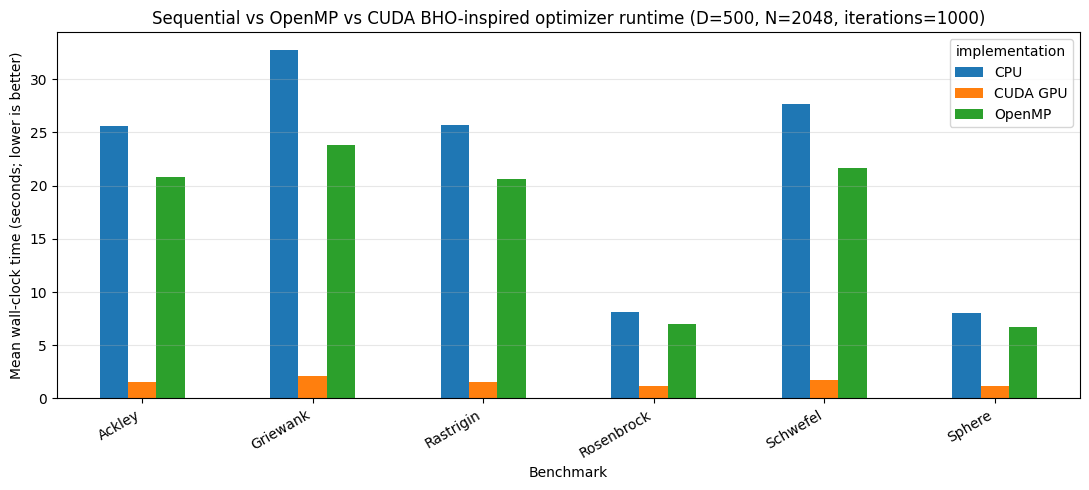

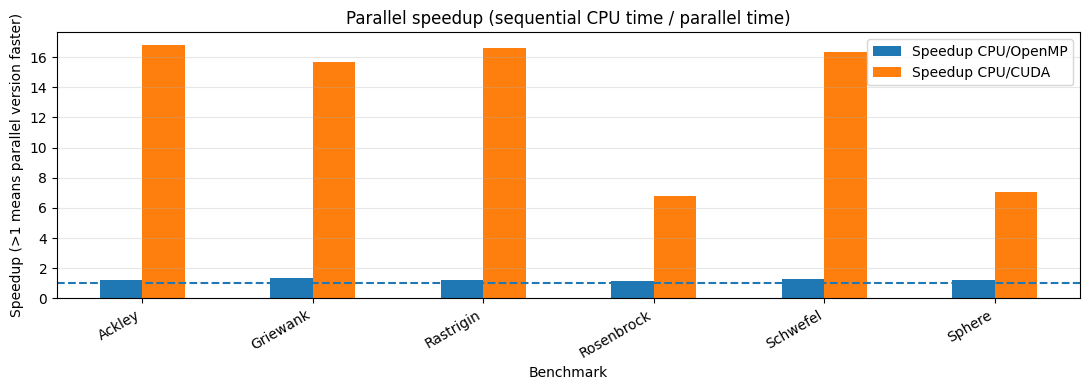

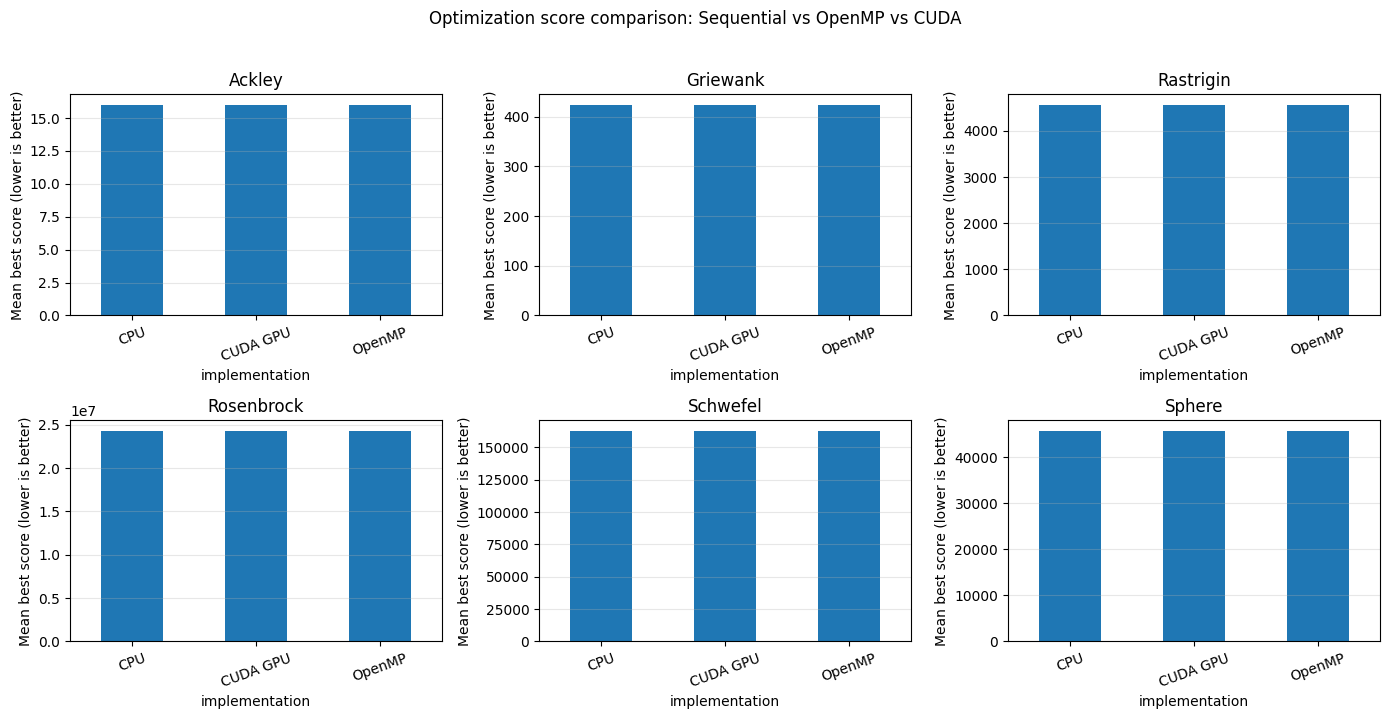

In [22]:
ax = times.plot(kind="bar", figsize=(11, 5))
ax.set_title(f"Sequential vs OpenMP vs CUDA BHO-inspired optimizer runtime (D={D}, N={POPULATION}, iterations={ITERATIONS})")
ax.set_ylabel("Mean wall-clock time (seconds; lower is better)")
ax.set_xlabel("Benchmark")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

ax = comparison[["Speedup CPU/OpenMP", "Speedup CPU/CUDA"]].plot(kind="bar", figsize=(11, 4))
ax.axhline(1.0, linestyle="--")
ax.set_title("Parallel speedup (sequential CPU time / parallel time)")
ax.set_ylabel("Speedup (>1 means parallel version faster)")
ax.set_xlabel("Benchmark")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

functions = list(scores.index)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, fn in zip(axes.flat, functions):
    scores.loc[fn].plot(kind="bar", ax=ax)
    ax.set_title(fn)
    ax.set_ylabel("Mean best score (lower is better)")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)
for ax in axes.flat[len(functions):]:
    ax.set_visible(False)
fig.suptitle("Optimization score comparison: Sequential vs OpenMP vs CUDA", y=1.02)
plt.tight_layout()
plt.show()


## 7. Scaling experiments and reporting

- First verify the run at `D=30`, `N=256`.
- Then try `D=100`, `N=512` and `D=300`, `N=1024` if runtime allows.
- Keep `ITERATIONS` and `REPEATS` identical between Sequential, OpenMP, and CUDA.
- Set `OMP_THREADS = 4` in the benchmark cell to control the number of OpenMP CPU threads.
- Report CPU/GPU model, thread count, dimension, population, iterations, repeats, mean runtime, speedup, and mean/std best score.
- The best score is stochastic and may not match the known optimum. Runtime alone does not establish optimization quality.
- The CUDA implementation is GPU-resident, while the OpenMP version uses shared-memory CPU parallelism. Compare end-to-end wall-clock time.
- Note: these implementations are a BHO-inspired comparison variant, not a line-by-line reproduction of every mechanism in the paper (K-means, QPRS, and Explorpolis).
